# Topological Band Theory: Static, Driven, and Anomalous

**Amaira Goel** · IIT Kanpur · [github.com/amairagoel](https://github.com/amairagoel)

---

This notebook builds three models from scratch in NumPy and checks each against
a result known analytically before plotting anything. It runs top to bottom in
Colab with no installation and no local files.

| Part | Model | Claim it establishes |
|---|---|---|
| 1 | Haldane model | A gapped 2D band structure carries an integer Chern number that counts edge channels |
| 2 | Circularly driven graphene | Driving *generates* the Haldane model — the static model is a high-frequency limit |
| 3 | Driven square lattice (RLBL) | In a driven system the Chern number stops counting edge channels altogether |

The thread running through all three is a single question: **when does a
topological invariant actually classify a phase, and what happens at the edge
of its validity?**

Part 3 is the point. It exhibits a driven system whose bulk Chern numbers are
all zero — the bulk says "trivial" — while chiral edge modes traverse the
entire quasienergy zone. The static bulk–boundary correspondence fails there,
and a different invariant is needed.

### A note on method

Every part has a validation block that prints `PASS`/`FAIL` against analytically
known results. Three real errors were caught this way while writing it: a sign
convention, a factor of two in the Haldane mass, and a Brillouin-zone sampling
condition. They are documented where they occur rather than silently fixed.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "font.size": 10, "axes.linewidth": 0.8,
    "figure.dpi": 120, "savefig.bbox": "tight",
})
BLUE, RED, GREEN, GREY = "#3b6ea5", "#c1504a", "#4a7c4a", "#b8b8b8"

PASSED, FAILED = [], []

def check(name, condition, detail=""):
    '''Record and print a validation result.'''
    (PASSED if condition else FAILED).append(name)
    print(f"{'PASS' if condition else 'FAIL'}  {name}" + (f"   {detail}" if detail else ""))

print("ready")

ready


---
# Part 1 — The Haldane model

Haldane (1988) showed that a quantised Hall conductance does not require a
magnetic field. A honeycomb lattice with complex next-nearest-neighbour hopping
breaks time-reversal symmetry locally while the net flux through a unit cell
stays zero, and the result is an insulator with chiral edge states.

The Bloch Hamiltonian is $H(\mathbf{k}) = d_0\mathbb{1} + \mathbf{d}\cdot\boldsymbol{\sigma}$ with

$$d_x + i d_y = t_1\sum_j e^{i\mathbf{k}\cdot\boldsymbol{\delta}_j},
\qquad d_z = M - 2t_2\sin\phi\sum_j \sin(\mathbf{k}\cdot\mathbf{a}_j).$$

The gap closes, and the topology changes, when $|M| = 3\sqrt{3}\,t_2|\sin\phi|$.
That closed-form boundary is what we validate against.

In [2]:
# Nearest-neighbour vectors (A -> B); lattice constant a = 1
DELTA = np.array([
    [0.0,  1.0/np.sqrt(3.0)],
    [-0.5, -0.5/np.sqrt(3.0)],
    [0.5,  -0.5/np.sqrt(3.0)],
])

# Next-nearest-neighbour vectors (within one sublattice)
A_VEC = np.array([DELTA[2]-DELTA[1], DELTA[0]-DELTA[2], DELTA[1]-DELTA[0]])
B_MAT = 2.0*np.pi*np.linalg.inv(np.array([A_VEC[0], A_VEC[1]])).T

PAULI = np.array([
    [[0, 1], [1, 0]],
    [[0, -1j], [1j, 0]],
    [[1, 0], [0, -1]],
], dtype=complex)


def d_vector(k, t1=1.0, t2=0.1, phi=np.pi/2, M=0.0):
    k = np.atleast_2d(np.asarray(k, dtype=float))
    kd, ka = k @ DELTA.T, k @ A_VEC.T
    d0 = 2.0*t2*np.cos(phi)*np.cos(ka).sum(-1)
    dx = t1*np.cos(kd).sum(-1)
    dy = t1*np.sin(kd).sum(-1)
    dz = M - 2.0*t2*np.sin(phi)*np.sin(ka).sum(-1)
    return d0, dx, dy, dz


def hamiltonian(k, **p):
    d0, dx, dy, dz = d_vector(k, **p)
    return (d0[..., None, None]*np.eye(2)
            + dx[..., None, None]*PAULI[0]
            + dy[..., None, None]*PAULI[1]
            + dz[..., None, None]*PAULI[2])


def gap(k, **p):
    '''Full band splitting 2|d| -- note this is twice the Dirac *mass*.'''
    _, dx, dy, dz = d_vector(k, **p)
    return 2.0*np.sqrt(dx**2 + dy**2 + dz**2)


def phase_boundary_M(t2=0.1, phi=np.pi/2):
    return 3.0*np.sqrt(3.0)*t2*abs(np.sin(phi))

print("Haldane model defined")

Haldane model defined


### Chern number without choosing a gauge

If the Chern number is nonzero there is **no** smooth global choice of phase for
the Bloch states over the Brillouin zone — that obstruction is exactly what the
invariant measures. So differentiating $\langle u|\partial_k u\rangle$ naively
fails.

The Fukui–Hatsugai–Suzuki construction sidesteps this. Build link variables from
overlaps of neighbouring states, normalise them to unit modulus, and take the
phase of the product around each plaquette. Every arbitrary phase cancels
between the links, and the sum over plaquettes is an exact integer even on a
coarse grid.

In [3]:
def _bz_grid(n):
    f = np.arange(n)/n
    f1, f2 = np.meshgrid(f, f, indexing="ij")
    return f1[..., None]*B_MAT[0] + f2[..., None]*B_MAT[1]


def lower_band_states(k, **p):
    return np.linalg.eigh(hamiltonian(k, **p))[1][..., :, 0]


def _chern_from_states(u):
    '''Phase of the plaquette loop -- gauge invariant by construction.'''
    ux = np.sum(u.conj()*np.roll(u, -1, axis=0), -1)
    uy = np.sum(u.conj()*np.roll(u, -1, axis=1), -1)
    ux /= np.abs(ux); uy /= np.abs(uy)
    loop = ux*np.roll(uy, -1, axis=0)/(np.roll(ux, -1, axis=1)*uy)
    return np.angle(loop)


def berry_curvature(n=120, **p):
    return _chern_from_states(lower_band_states(_bz_grid(n), **p))


def chern_number(n=120, **p):
    return berry_curvature(n, **p).sum()/(2.0*np.pi)

print("Chern machinery defined")

Chern machinery defined


### Validation

Three things worth flagging, each of which caught a genuine error:

- **The sign of $C$ is a convention**, fixed by the ordering of `DELTA` and
  `A_VEC`, not by physics. What is physical is $|C| = 1$ and that $C$ reverses
  under $\phi \to -\phi$. The first draft asserted $C = -1$ and was wrong.
- **The Dirac points sit at fractional coordinates $(1/3, 2/3)$**, so a uniform
  $n\times n$ grid only samples them when $3 \mid n$. Checking gap closure by
  minimising over a grid silently fails for most $n$.
- **`gap` returns the full splitting $2|d|$.** The familiar $3\sqrt{3}t_2$ is
  the *mass*, i.e. the half-gap. This factor of two matters in Part 2.

In [4]:
p_topo = dict(t1=1.0, t2=0.1, phi=np.pi/2, M=0.0)
Mc = phase_boundary_M(0.1, np.pi/2)
Kp = np.array([-4*np.pi/3, 0.0])

c = chern_number(n=90, **p_topo)
check("chern_quantised", abs(c-round(c)) < 1e-6, f"C = {c:.12f}")
check("chern_magnitude_one", abs(round(c)) == 1, f"C = {round(c):+d}")

cm = chern_number(n=90, t1=1.0, t2=0.1, phi=-np.pi/2, M=0.0)
check("sign_flips_with_phi", round(c) == -round(cm), f"{round(c):+d} vs {round(cm):+d}")

ct = chern_number(n=90, t1=1.0, t2=0.1, phi=np.pi/2, M=2*Mc)
check("trivial_beyond_boundary", round(ct) == 0, f"C = {round(ct):+d}")

vals = [round(chern_number(n=n, **p_topo)) for n in (40, 70, 110)]
check("grid_independent", len(set(vals)) == 1, f"n=40,70,110 -> {vals}")

g_at = gap(Kp, t1=1.0, t2=0.1, phi=np.pi/2, M=Mc)[0]
g_off = gap(Kp, t1=1.0, t2=0.1, phi=np.pi/2, M=0.8*Mc)[0]
check("gap_closes_at_boundary", g_at < 1e-10, f"gap(M_c) = {g_at:.2e}")
check("gap_open_away", g_off > 1e-2, f"gap(0.8 M_c) = {g_off:.4f}")

# the 3|n sampling condition, made explicit
hit = gap(_bz_grid(300).reshape(-1,2), t1=1.0, t2=0.1, phi=np.pi/2, M=Mc).min()
miss = gap(_bz_grid(400).reshape(-1,2), t1=1.0, t2=0.1, phi=np.pi/2, M=Mc).min()
check("dirac_point_needs_3|n", hit < 1e-10 < miss, f"n=300: {hit:.1e}   n=400: {miss:.1e}")

PASS  chern_quantised   C = 1.000000000000
PASS  chern_magnitude_one   C = +1
PASS  sign_flips_with_phi   +1 vs -1
PASS  trivial_beyond_boundary   C = +0
PASS  grid_independent   n=40,70,110 -> [1, 1, 1]
PASS  gap_closes_at_boundary   gap(M_c) = 8.88e-16
PASS  gap_open_away   gap(0.8 M_c) = 0.2078


PASS  dirac_point_needs_3|n   n=300: 8.9e-16   n=400: 1.8e-02


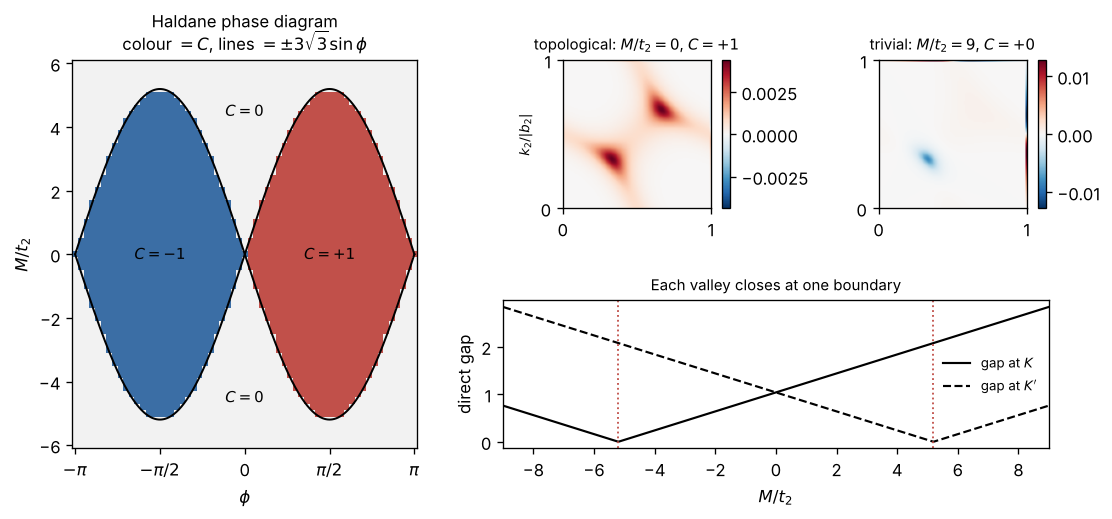

In [5]:
def haldane_phase_diagram(n_phi=61, n_M=61, grid=60, t2=0.1):
    phis = np.linspace(-np.pi, np.pi, n_phi)
    Ms = np.linspace(-6.0, 6.0, n_M)
    C = np.array([[round(chern_number(n=grid, t1=1.0, t2=t2, phi=ph, M=m*t2))
                   for ph in phis] for m in Ms])
    return phis, Ms, C

t2 = 0.1
phis, Ms, Cmap = haldane_phase_diagram(t2=t2)

fig = plt.figure(figsize=(10.5, 4.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1.5, 1, 1], hspace=0.62, wspace=0.32)

ax = fig.add_subplot(gs[:, 0])
cmap = mpl.colors.ListedColormap([BLUE, "#f2f2f2", RED])
norm = mpl.colors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)
ax.pcolormesh(phis, Ms, Cmap, cmap=cmap, norm=norm, shading="auto")
pb = np.linspace(-np.pi, np.pi, 400)
ax.plot(pb, 3*np.sqrt(3)*np.sin(pb), "k-", lw=1.2)
ax.plot(pb, -3*np.sqrt(3)*np.sin(pb), "k-", lw=1.2)
ax.set_xlabel(r"$\phi$"); ax.set_ylabel(r"$M/t_2$")
ax.set_title("Haldane phase diagram\n" r"colour $=C$, lines $=\pm3\sqrt{3}\sin\phi$", fontsize=10)
ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax.set_xticklabels([r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
for lab, xy in [("+1", (np.pi/2, 0)), ("-1", (-np.pi/2, 0)), ("0", (0, 4.5)), ("0", (0, -4.5))]:
    ax.annotate(f"$C={lab}$", xy, ha="center", va="center", fontsize=9)

for col, (ph, Mr, lab) in enumerate([(np.pi/2, 0.0, "topological"), (np.pi/2, 9.0, "trivial")]):
    a = fig.add_subplot(gs[0, col+1])
    F = berry_curvature(n=120, t1=1.0, t2=t2, phi=ph, M=Mr*t2)
    v = np.abs(F).max()
    im = a.imshow(F.T, origin="lower", cmap="RdBu_r", vmin=-v, vmax=v, extent=[0,1,0,1])
    a.set_title(f"{lab}: $M/t_2={Mr:g}$, $C={round(F.sum()/(2*np.pi)):+d}$", fontsize=9)
    a.set_xticks([0,1]); a.set_yticks([0,1])
    if col == 0: a.set_ylabel("$k_2/|b_2|$", fontsize=8)
    fig.colorbar(im, ax=a, fraction=0.046)

a = fig.add_subplot(gs[1, 1:])
Mr = np.linspace(-9, 9, 500)
for (lab, pt), st in zip({r"$K$": -Kp, r"$K'$": Kp}.items(), ["k-", "k--"]):
    a.plot(Mr, [gap(pt, t1=1.0, t2=t2, phi=np.pi/2, M=m*t2)[0] for m in Mr],
           st, lw=1.3, label=f"gap at {lab}")
for s in (+1, -1):
    a.axvline(s*Mc/t2, color=RED, ls=":", lw=1.1)
a.set_xlabel(r"$M/t_2$"); a.set_ylabel("direct gap")
a.set_title(r"Each valley closes at one boundary", fontsize=9)
a.legend(fontsize=8, frameon=False); a.margins(x=0)
plt.show()

---
# Part 2 — Driving generates the Haldane model

Shine circularly polarised light on plain graphene. The vector potential enters
by Peierls substitution, $\mathbf{k}\to\mathbf{k}+\mathbf{A}(t)$ with
$\mathbf{A}(t) = A(\cos\Omega t,\ h\sin\Omega t)$ and helicity $h=\pm1$.

Graphene alone is gapless. But the drive generates an effective
next-nearest-neighbour hopping with a complex phase — precisely the Haldane
term — and opens a gap at the Dirac points. **The static model of Part 1 is the
high-frequency limit of this driven one.**

Because the drive is periodic, states are labelled by *quasienergy*: the
eigenphases of the one-period evolution operator $U(T)$, defined only modulo
$\Omega$. Quasienergy lives on a circle, not a line — a fact that becomes
essential in Part 3.

> **Helicity is not the sign of $A$.** Reversing $A\to-A$ gives the *same*
> circulation shifted by half a period. Handedness lives in the relative sign of
> the two components, so it needs its own parameter. Getting this wrong makes
> the Chern number fail to flip, which is how the error was caught.

In [6]:
def _expm_2x2_traceless(dx, dy, dz, dt):
    '''exp(-i d.sigma dt) exactly: (d.sigma)^2 = |d|^2 I closes it on cos/sin.'''
    n = np.sqrt(dx**2 + dy**2 + dz**2)
    c = np.cos(n*dt)
    s = np.where(n > 1e-14, np.sin(n*dt)/np.where(n > 1e-14, n, 1.0), dt)
    return (c[..., None, None]*np.eye(2).astype(complex)
            - 1j*s[..., None, None]*(dx[..., None, None]*PAULI[0]
                                     + dy[..., None, None]*PAULI[1]
                                     + dz[..., None, None]*PAULI[2]))


def floquet_operator(k, t1=1.0, A=0.5, omega=10.0, n_steps=400, helicity=1):
    '''Time-ordered U(T) by midpoint slicing; error O(dt^2).'''
    k = np.atleast_2d(np.asarray(k, dtype=float))
    T = 2.0*np.pi/omega
    dt = T/n_steps
    U = np.broadcast_to(np.eye(2, dtype=complex), k.shape[:-1]+(2,2)).copy()
    for n in range(n_steps):
        tmid = (n+0.5)*dt
        a_t = A*np.array([np.cos(omega*tmid), helicity*np.sin(omega*tmid)])
        kd = (k + a_t) @ DELTA.T
        dx, dy = t1*np.cos(kd).sum(-1), t1*np.sin(kd).sum(-1)
        U = _expm_2x2_traceless(dx, dy, np.zeros_like(dx), dt) @ U
    return U


def quasienergies(k, t1=1.0, A=0.5, omega=10.0, n_steps=400, helicity=1):
    U = floquet_operator(k, t1, A, omega, n_steps, helicity)
    return np.sort(-np.angle(np.linalg.eigvals(U))/(2.0*np.pi/omega), axis=-1)


def floquet_states(k, band=0, t1=1.0, A=0.5, omega=10.0, n_steps=400, helicity=1):
    U = floquet_operator(k, t1, A, omega, n_steps, helicity)
    ev, vecs = np.linalg.eig(U)
    eps = -np.angle(ev)/(2.0*np.pi/omega)
    order = np.argsort(eps, axis=-1)
    idx = np.take_along_axis(order, np.full(order.shape[:-1]+(1,), band), -1)
    pick = np.broadcast_to(idx[..., None, :], vecs.shape[:-1]+(1,))
    return np.take_along_axis(vecs, pick, -1)[..., 0]


def floquet_chern(n=40, band=0, **p):
    return _chern_from_states(floquet_states(_bz_grid(n), band=band, **p)).sum()/(2*np.pi)


def gap_at_dirac(t1=1.0, A=0.5, omega=10.0, n_steps=400, helicity=1):
    K = np.array([4.0*np.pi/3.0, 0.0])
    e = quasienergies(K, t1, A, omega, n_steps, helicity)[0]
    return e[1] - e[0]


# Measured numerically to six digits, not quoted from a paper: the coefficient
# is convention dependent (|delta| = 1/sqrt(3) here, A dimensionless).
HIGHFREQ_COEFF = 1.5

def predicted_gap_highfreq(t1=1.0, A=0.5, omega=10.0):
    '''Delta -> (3/2) t1^2 A^2 / Omega  as A -> 0.'''
    return HIGHFREQ_COEFF*t1**2*A**2/omega

def induced_t2(t1=1.0, A=0.5, omega=10.0):
    '''Haldane t2 the drive generates. Divides by 6*sqrt(3): full gap, not mass.'''
    return predicted_gap_highfreq(t1, A, omega)/(6.0*np.sqrt(3.0))

print("Floquet machinery defined")

Floquet machinery defined


In [7]:
kk = np.random.default_rng(0).normal(size=(8, 2))
U = floquet_operator(kk, A=0.7, omega=8.0, n_steps=300)
err = np.abs(U @ U.conj().transpose(0,2,1) - np.eye(2)).max()
check("U_unitary", err < 1e-12, f"max dev = {err:.2e}")

check("undriven_is_gapless", gap_at_dirac(A=0.0, omega=8.0) < 1e-12)

g = [gap_at_dirac(A=0.5, omega=10.0, n_steps=n) for n in (200, 400, 800)]
ratio = abs(g[2]-g[1])/abs(g[1]-g[0])
check("integrator_is_second_order", 0.2 < ratio < 0.3, f"error ratio = {ratio:.3f} (expect 0.25)")

oms = np.array([15., 20., 30., 40.])
slope = np.polyfit(np.log(oms), np.log([gap_at_dirac(A=0.3, omega=o, n_steps=900) for o in oms]), 1)[0]
check("gap_scales_as_1/Omega", abs(slope+1) < 0.02, f"slope = {slope:.4f}")

As = np.array([0.05, 0.1, 0.2])
slopeA = np.polyfit(np.log(As), np.log([gap_at_dirac(A=a, omega=40., n_steps=1200) for a in As]), 1)[0]
check("gap_scales_as_A^2", abs(slopeA-2) < 0.02, f"slope = {slopeA:.4f}")

r = gap_at_dirac(A=0.02, omega=40., n_steps=1500)/predicted_gap_highfreq(A=0.02, omega=40.)
check("coefficient_is_3/2", abs(r-1) < 1e-3, f"ratio = {r:.6f}")

cp = floquet_chern(n=36, A=0.5, omega=10., n_steps=150, helicity=+1)
cm = floquet_chern(n=36, A=0.5, omega=10., n_steps=150, helicity=-1)
check("chern_flips_with_helicity", round(cp) == -round(cm) != 0, f"{round(cp):+d} vs {round(cm):+d}")
check("helicity_preserves_gap",
      abs(gap_at_dirac(A=.5, omega=10., helicity=1) - gap_at_dirac(A=.5, omega=10., helicity=-1)) < 1e-12)

# the central claim of Part 2
A_, om_ = 0.2, 30.0
t2_ind = induced_t2(A=A_, omega=om_)
r2 = gap_at_dirac(A=A_, omega=om_, n_steps=1200)/gap(Kp, t1=1.0, t2=t2_ind, phi=np.pi/2, M=0.0)[0]
check("driven_reproduces_static_haldane", abs(r2-1) < 2e-2,
      f"Floquet/static gap = {r2:.4f},  induced t2 = {t2_ind:.5f}")

PASS  U_unitary   max dev = 3.00e-15
PASS  undriven_is_gapless


PASS  integrator_is_second_order   error ratio = 0.250 (expect 0.25)


PASS  gap_scales_as_1/Omega   slope = -0.9997
PASS  gap_scales_as_A^2   slope = 1.9975


PASS  coefficient_is_3/2   ratio = 0.999961
PASS  chern_flips_with_helicity   +1 vs -1
PASS  helicity_preserves_gap


PASS  driven_reproduces_static_haldane   Floquet/static gap = 0.9962,  induced t2 = 0.00019


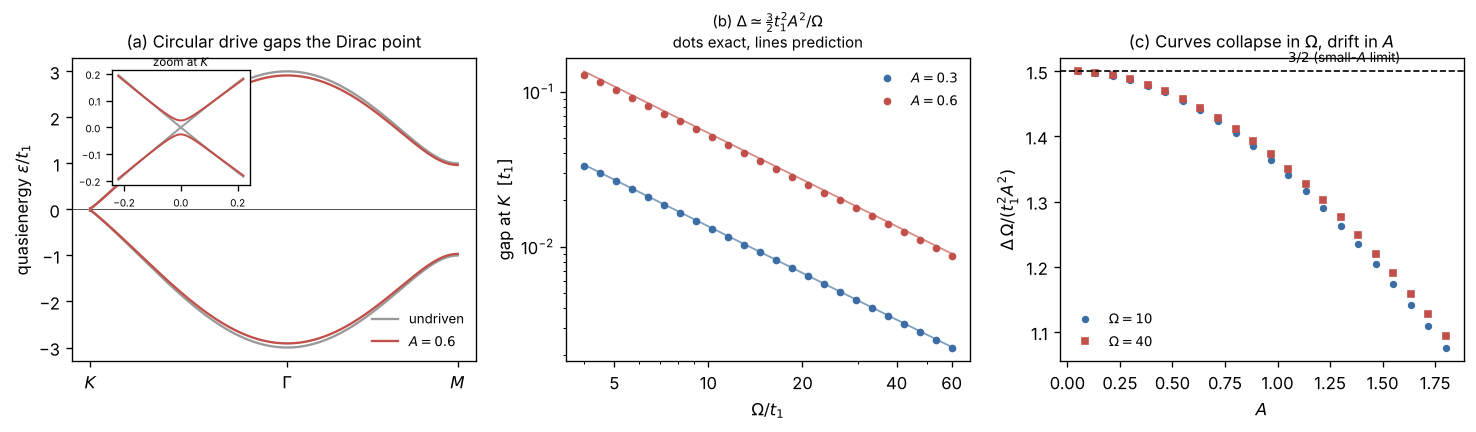

In [8]:
from matplotlib.ticker import ScalarFormatter

fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.7))

ax = axes[0]
G, K, M = np.array([0.,0.]), np.array([4*np.pi/3, 0.]), np.array([np.pi, np.pi/np.sqrt(3)])
segs, ticks, xs, pos = [], [0.0], [], 0.0
for p0, p1 in [(K, G), (G, M)]:
    segs.append(np.linspace(0,1,160)[:,None]*(p1-p0)+p0)
    d = np.linalg.norm(p1-p0); xs.append(np.linspace(pos, pos+d, 160)); pos += d; ticks.append(pos)
kpath, xpath = np.vstack(segs), np.concatenate(xs)
for A, lab, col in [(0.0, "undriven", "#9a9a9a"), (0.6, r"$A=0.6$", RED)]:
    e = quasienergies(kpath, A=A, omega=10.0, n_steps=400)
    ax.plot(xpath, e[:,0], color=col, lw=1.4, label=lab); ax.plot(xpath, e[:,1], color=col, lw=1.4)
ax.set_xticks(ticks); ax.set_xticklabels(["$K$", r"$\Gamma$", "$M$"])
ax.set_ylabel(r"quasienergy $\varepsilon/t_1$"); ax.axhline(0, color="k", lw=0.4, zorder=0)
ax.set_title("(a) Circular drive gaps the Dirac point", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="lower right")
ins = ax.inset_axes([0.10, 0.58, 0.34, 0.38])
kz = np.linspace(-0.22, 0.22, 200)[:,None]*np.array([1.,0.]) + K
for A, col in [(0.0, "#9a9a9a"), (0.6, RED)]:
    e = quasienergies(kz, A=A, omega=10.0, n_steps=600)
    ins.plot(kz[:,0]-K[0], e[:,0], color=col, lw=1.2); ins.plot(kz[:,0]-K[0], e[:,1], color=col, lw=1.2)
ins.set_title("zoom at $K$", fontsize=7, pad=2); ins.tick_params(labelsize=6); ins.set_xticks([-0.2,0,0.2])

ax = axes[1]
oms = np.logspace(np.log10(4.), np.log10(60.), 24)
for A, col in [(0.3, BLUE), (0.6, RED)]:
    ax.loglog(oms, [gap_at_dirac(A=A, omega=o, n_steps=1200) for o in oms], "o", ms=3.6, color=col, label=f"$A={A}$")
    ax.loglog(oms, predicted_gap_highfreq(A=A, omega=oms), "-", color=col, lw=1.1, alpha=0.65)
ax.set_xlabel(r"$\Omega/t_1$"); ax.set_ylabel(r"gap at $K$  $[t_1]$")
ax.set_title(r"(b) $\Delta \simeq \frac{3}{2}t_1^2A^2/\Omega$" "\ndots exact, lines prediction", fontsize=9)
ax.legend(fontsize=8, frameon=False)
ax.set_xticks([5,10,20,40,60]); ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())

ax = axes[2]
As = np.linspace(0.05, 1.8, 22)
for om, col, mk in [(10., BLUE, "o"), (40., RED, "s")]:
    ax.plot(As, [gap_at_dirac(A=a, omega=om, n_steps=1400)*om/a**2 for a in As], mk, ms=3.4, color=col, label=rf"$\Omega={om:g}$")
ax.axhline(1.5, color="k", ls="--", lw=1)
ax.text(1.05, 1.513, r"$3/2$ (small-$A$ limit)", fontsize=8)
ax.set_xlabel("$A$"); ax.set_ylabel(r"$\Delta\,\Omega/(t_1^2A^2)$")
ax.set_title("(c) Curves collapse in $\\Omega$, drift in $A$", fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout(); plt.show()

Panel (c) separates two different approximations that are easy to conflate. The
$\Omega=10$ and $\Omega=40$ points lie on top of each other, so the $1/\Omega$
(Magnus) scaling is excellent even at modest frequency. What drifts is the
coefficient, away from $3/2$ as $A$ grows — that is the $O(A^4)$ correction, not
a failure of the high-frequency expansion. Plotting a single "relative error"
mixes them and makes Magnus look like it is breaking down when it is not.

---
# Part 3 — Where the Chern number stops working

Everything so far assumed the usual rule: compute an integer from the bulk, and
it counts the chiral edge channels. **In driven systems that rule fails.**

Rudner, Lindner, Berg and Levin (PRX 3, 031005, 2013) constructed the clean
counterexample. Take a checkerboard square lattice and switch on its four
nearest-neighbour bonds one at a time, cyclically around a plaquette, then apply
a staggered sublattice potential in a fifth step.

Tune each hopping step to a perfect particle swap, $J\tau = \pi/2$. A bulk
particle then hops right, up, left, down — around a closed loop — and lands
exactly where it started. The one-period operator is literally the identity:

$$U(T) = \mathbb{1}\quad\text{for every }\mathbf{k}\ \Longrightarrow\ C = 0
\ \text{for both bands.}$$

A particle *on the edge* cannot complete that loop, because one bond has nothing
on the other side. Instead of returning home it is shunted one cell along the
edge, every period. That is a chiral edge channel.

So the bulk says "nothing happened" and the edge says "I moved," and both are
correct. **The interesting motion happened mid-period, and the Chern number —
built only from $U(T)$ — never looked.**

### Two details that are load-bearing

- **The cyclic order matters.** Right → up → left → down closes the loop. Any
  other ordering leaves a residual $\mathbf{k}$-dependent phase. Tested below by
  scrambling it.
- **The fifth step is not decoration.** With four hopping steps alone the two
  quasienergy bands *touch* at $\varepsilon=0$ for every $J$, leaving no gap to
  host an edge mode and no well-defined Chern number. The staggered potential
  opens it. Also tested below.

In [9]:
# (dp, dq) cell offsets of the active A->B bond in each step: right, up, left, down
STEP_OFFSETS = ((0,0), (0,-1), (-1,-1), (-1,0))
N_STEPS = 5                      # four hoppings + one staggered potential
JT_ANOMALOUS = 2.5*np.pi         # J*tau = pi/2, the perfect-swap point


def bulk_floquet_operator_sq(k, JT=JT_ANOMALOUS, dT=0.0):
    k = np.atleast_2d(np.asarray(k, dtype=float))
    Jtau = JT/N_STEPS
    c, s = np.cos(Jtau), np.sin(Jtau)
    U = np.broadcast_to(np.eye(2, dtype=complex), k.shape[:-1]+(2,2)).copy()
    for dp, dq in STEP_OFFSETS:
        th = k[..., 0]*dp + k[..., 1]*dq
        st = np.empty(k.shape[:-1]+(2,2), dtype=complex)
        st[...,0,0] = st[...,1,1] = c
        st[...,0,1] = 1j*s*np.exp(1j*th)
        st[...,1,0] = 1j*s*np.exp(-1j*th)
        U = st @ U
    dtau = dT/N_STEPS
    stag = np.zeros(k.shape[:-1]+(2,2), dtype=complex)
    stag[...,0,0] = np.exp(-1j*dtau); stag[...,1,1] = np.exp(1j*dtau)
    return stag @ U


def _sq_grid(n):
    f = 2.0*np.pi*np.arange(n)/n
    kp, kq = np.meshgrid(f, f, indexing="ij")
    return np.stack([kp, kq], -1)


def bulk_quasienergies_sq(k, JT=JT_ANOMALOUS, dT=0.0):
    return np.sort(-np.angle(np.linalg.eigvals(bulk_floquet_operator_sq(k, JT, dT))), -1)


def bulk_chern_sq(n=36, band=0, JT=JT_ANOMALOUS, dT=0.0):
    U = bulk_floquet_operator_sq(_sq_grid(n), JT, dT)
    ev, vecs = np.linalg.eig(U)
    order = np.argsort(-np.angle(ev), -1)
    idx = np.take_along_axis(order, np.full(order.shape[:-1]+(1,), band), -1)
    pick = np.broadcast_to(idx[..., None, :], vecs.shape[:-1]+(1,))
    return _chern_from_states(np.take_along_axis(vecs, pick, -1)[..., 0]).sum()/(2*np.pi)


def bulk_gaps_sq(n=50, JT=JT_ANOMALOUS, dT=0.0):
    '''Quasienergy is a circle: there is a gap at 0 AND one at the zone edge pi.'''
    e = bulk_quasienergies_sq(_sq_grid(n).reshape(-1,2), JT, dT)
    return float(e[:,1].min()-e[:,0].max()), float(2*np.pi+e[:,0].min()-e[:,1].max())

print("RLBL bulk defined")

RLBL bulk defined


In [10]:
def _stagger(dim, dT):
    d = np.empty(dim, dtype=complex)
    d[0::2] = np.exp(-1j*dT/N_STEPS); d[1::2] = np.exp(1j*dT/N_STEPS)
    return np.diag(d)


def ribbon_floquet_operator(kp, n_cells=20, JT=JT_ANOMALOUS, dT=0.0, ring=False):
    '''Periodic in p, open in q (or closed into a ring when ring=True).

    In every step each site belongs to at most one bond, so the step
    Hamiltonian is block diagonal in 2x2 blocks and its exponential is exact.
    No Trotter error, no matrix exponential. Sites whose partner lies outside
    the ribbon simply do not evolve -- that missing bond IS the edge mode.
    '''
    Jtau = JT/N_STEPS
    c, s = np.cos(Jtau), np.sin(Jtau)
    dim = 2*n_cells
    U = np.eye(dim, dtype=complex)
    for dp, dq in STEP_OFFSETS:
        th = kp*dp
        st = np.eye(dim, dtype=complex)
        for q in range(n_cells):
            qb = (q+dq) % n_cells if ring else q+dq
            if not ring and not (0 <= qb < n_cells):
                continue
            ia, ib = 2*q, 2*qb+1
            st[ia,ia] = st[ib,ib] = c
            st[ia,ib] = 1j*s*np.exp(1j*th)
            st[ib,ia] = 1j*s*np.exp(-1j*th)
        U = st @ U
    return _stagger(dim, dT) @ U


def ribbon_spectrum(kp, n_cells=20, JT=JT_ANOMALOUS, dT=0.0):
    ev, vecs = np.linalg.eig(ribbon_floquet_operator(kp, n_cells, JT, dT))
    eps = -np.angle(ev); o = np.argsort(eps)
    return eps[o], vecs[:, o]


def edge_weight(vec, n_cells, frac=0.2):
    '''Weight within frac of each edge. Bulk state ~ frac each; edge state ~ 1.'''
    w = (np.abs(vec)**2).reshape(n_cells, 2).sum(-1)
    m = max(1, int(round(frac*n_cells)))
    return float(w[:m].sum()), float(w[-m:].sum())

print("RLBL ribbon defined")

RLBL ribbon defined


### Validation

The strongest check here is `ring_reproduces_bulk`. The ribbon is assembled
site-by-site from the bond table in real space; the bulk comes from an
independent analytic $2\times2$ Bloch formula. Closing the ribbon into a ring
must reproduce the bulk spectrum exactly. Any error in the offsets, the step
ordering or the Bloch phases would break it.

In [11]:
DT = 1.0
JT_A, JT_T = 2.0*np.pi, 0.4*np.pi   # anomalous / trivial

kk = np.random.default_rng(1).uniform(0, 2*np.pi, size=(10,2))
U = bulk_floquet_operator_sq(kk, JT=JT_A, dT=DT)
check("bulk_unitary", np.abs(U @ U.conj().transpose(0,2,1) - np.eye(2)).max() < 1e-13)

Ur = ribbon_floquet_operator(0.7, 12, JT_A, DT)
check("ribbon_unitary", np.abs(Ur @ Ur.conj().T - np.eye(24)).max() < 1e-13)

# two independent code paths must agree
N, kp0 = 8, 0.83
ring = np.sort(-np.angle(np.linalg.eigvals(ribbon_floquet_operator(kp0, N, JT_A, DT, ring=True))))
bulk = np.sort(np.concatenate([bulk_quasienergies_sq(np.array([kp0, 2*np.pi*m/N]), JT_A, DT)[0]
                               for m in range(N)]))
check("ring_reproduces_bulk", np.abs(ring-bulk).max() < 1e-12, f"max dev = {np.abs(ring-bulk).max():.1e}")

# the defining property, at the perfect-swap point with no staggering
Uid = bulk_floquet_operator_sq(kk, JT=JT_ANOMALOUS, dT=0.0)
check("bulk_loop_closes", np.abs(Uid-np.eye(2)).max() < 1e-12,
      f"max |U - 1| = {np.abs(Uid-np.eye(2)).max():.1e}")

# cyclic ordering is essential, not cosmetic
_orig = STEP_OFFSETS
STEP_OFFSETS = (_orig[0], _orig[2], _orig[1], _orig[3])
scr = np.abs(bulk_floquet_operator_sq(kk, JT=JT_ANOMALOUS, dT=0.0) - np.eye(2)).max()
STEP_OFFSETS = _orig
check("step_ordering_matters", scr > 0.1, f"scrambled: max |U - 1| = {scr:.3f}")

g0_bare, _ = bulk_gaps_sq(40, 1.2*np.pi, 0.0)
g0_stag, _ = bulk_gaps_sq(40, 1.2*np.pi, DT)
check("fifth_step_opens_zero_gap", g0_bare < 1e-6 < 1e-2 < g0_stag,
      f"without: {g0_bare:.2e}   with: {g0_stag:.4f}")

g0, gpi = bulk_gaps_sq(50, JT_A, DT)
check("both_gaps_open", g0 > 1e-2 and gpi > 1e-2, f"gap(0) = {g0:.3f},  gap(pi) = {gpi:.3f}")

PASS  bulk_unitary
PASS  ribbon_unitary
PASS  ring_reproduces_bulk   max dev = 7.2e-16
PASS  bulk_loop_closes   max |U - 1| = 4.7e-16
PASS  step_ordering_matters   scrambled: max |U - 1| = 2.000
PASS  fifth_step_opens_zero_gap   without: -4.06e-17   with: 0.0893
PASS  both_gaps_open   gap(0) = 0.329,  gap(pi) = 3.743


In [12]:
def in_gap_states(kp, N, JT, dT):
    '''In-gap ribbon states as (quasienergy, bottom weight, top weight).'''
    eps, vecs = ribbon_spectrum(kp, N, JT, dT)
    e = bulk_quasienergies_sq(_sq_grid(40).reshape(-1,2), JT, dT)
    lo_min, lo_max, hi_min, hi_max = e[:,0].min(), e[:,0].max(), e[:,1].min(), e[:,1].max()
    out = []
    for i, x in enumerate(eps):
        if (lo_max+1e-6 < x < hi_min-1e-6) or x > hi_max+1e-6 or x < lo_min-1e-6:
            b, t = edge_weight(vecs[:, i], N)
            out.append((x, b, t))
    return out

# --- the central result -------------------------------------------------
for band in (0, 1):
    ca = bulk_chern_sq(36, band, JT_A, DT)
    ct = bulk_chern_sq(36, band, JT_T, DT)
    check(f"chern_zero_anomalous_band{band}", abs(ca) < 1e-6, f"C = {ca:+.1e}")
    check(f"chern_zero_trivial_band{band}",  abs(ct) < 1e-6, f"C = {ct:+.1e}")

check("edge_states_in_anomalous_phase", len(in_gap_states(0.0, 20, JT_A, DT)) >= 2,
      f"{len(in_gap_states(0.0, 20, JT_A, DT))} in-gap states")
check("no_edge_states_in_trivial_phase",
      all(not in_gap_states(k, 20, JT_T, DT) for k in (0.0, 1.5, 3.0)))

for x, b, t in in_gap_states(1.5, 24, JT_A, DT):
    check(f"localised_eps={x:+.2f}", max(b,t) > 0.8 and min(b,t) < 0.2, f"bottom {b:.2f} / top {t:.2f}")

# counter-propagating?
vel = {}
for side in (0, 1):
    es = [ [x for x,b,t in in_gap_states(k, 24, JT_A, DT) if (b if side==0 else t) > 0.8][0]
           for k in (1.45, 1.55) ]
    vel[side] = (es[1]-es[0])/0.1
check("edge_modes_counter_propagate", vel[0]*vel[1] < 0,
      f"v_bottom = {vel[0]:+.2f},  v_top = {vel[1]:+.2f}")

counts = [len(in_gap_states(1.5, N, JT_A, DT)) for N in (16, 24, 32)]
check("edge_count_width_independent", len(set(counts)) == 1, f"N=16,24,32 -> {counts}")

PASS  chern_zero_anomalous_band0   C = +3.5e-17
PASS  chern_zero_trivial_band0   C = -1.1e-16
PASS  chern_zero_anomalous_band1   C = -3.5e-17
PASS  chern_zero_trivial_band1   C = -1.1e-16
PASS  edge_states_in_anomalous_phase   2 in-gap states
PASS  no_edge_states_in_trivial_phase
PASS  localised_eps=-1.44   bottom 0.00 / top 1.00
PASS  localised_eps=+1.44   bottom 1.00 / top 0.00
PASS  edge_modes_counter_propagate   v_bottom = -1.00,  v_top = +1.00
PASS  edge_count_width_independent   N=16,24,32 -> [2, 2, 2]


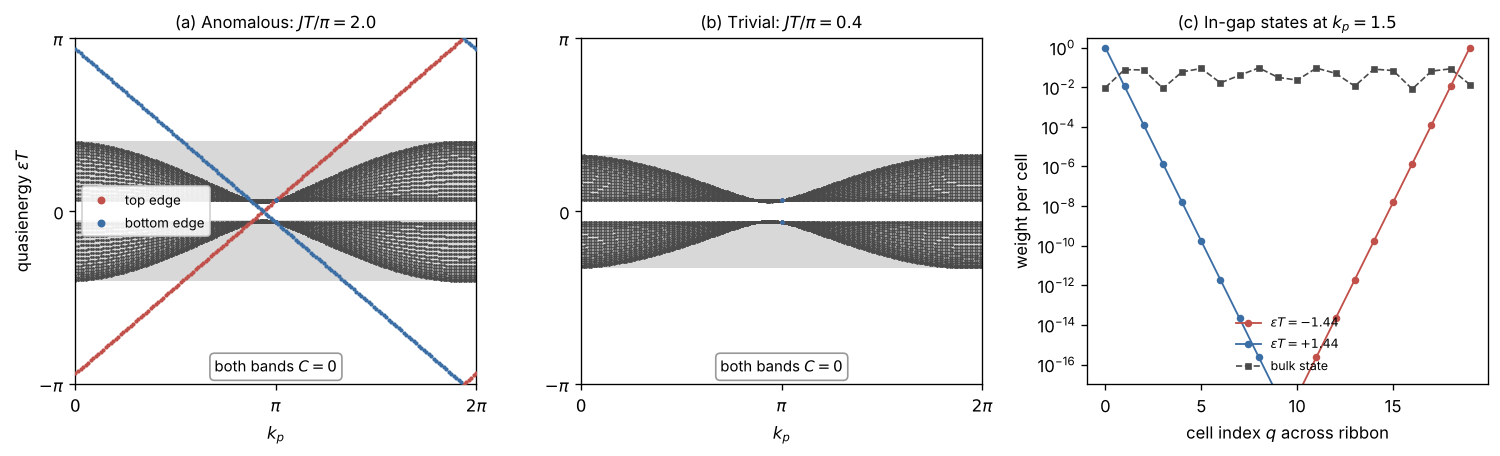

In [13]:
NC = 20

def bulk_extent(JT, dT, n=60):
    e = bulk_quasienergies_sq(_sq_grid(n).reshape(-1,2), JT, dT)
    return (e[:,0].min(), e[:,0].max()), (e[:,1].min(), e[:,1].max())

def ribbon_panel(ax, JT, title, n_kp=161):
    lo, hi = bulk_extent(JT, DT)
    for a, b in (lo, hi):
        ax.axhspan(a, b, color=GREY, alpha=0.55, lw=0, zorder=0)
    ke, ee, ce = [], [], []
    for kp in np.linspace(0, 2*np.pi, n_kp):
        eps, vecs = ribbon_spectrum(kp, NC, JT, DT)
        for i, x in enumerate(eps):
            b, t = edge_weight(vecs[:, i], NC)
            ke.append(kp); ee.append(x); ce.append(t-b)
    ke, ee, ce = np.array(ke), np.array(ee), np.array(ce)
    ax.plot(ke[np.abs(ce)<0.5], ee[np.abs(ce)<0.5], ".", ms=1.4, color="#4a4a4a", zorder=2)
    for m, col, lab in ((ce>=0.5, RED, "top edge"), (ce<=-0.5, BLUE, "bottom edge")):
        ax.plot(ke[m], ee[m], ".", ms=3.0, color=col, zorder=3, label=lab)
    ax.set_xlim(0, 2*np.pi); ax.set_ylim(-np.pi, np.pi)
    ax.set_xticks([0, np.pi, 2*np.pi]); ax.set_xticklabels(["$0$", r"$\pi$", r"$2\pi$"])
    ax.set_yticks([-np.pi, 0, np.pi]); ax.set_yticklabels([r"$-\pi$", "0", r"$\pi$"])
    ax.set_xlabel("$k_p$"); ax.set_title(title, fontsize=10)
    return lo, hi

fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9))

ribbon_panel(axes[0], JT_A, "(a) Anomalous: $JT/\\pi = 2.0$")
axes[0].set_ylabel(r"quasienergy $\varepsilon T$")
axes[0].legend(fontsize=8, frameon=True, framealpha=0.9, loc="center left", markerscale=2.5)
axes[0].text(0.5, 0.035, f"both bands $C = {round(bulk_chern_sq(36,0,JT_A,DT))}$",
             transform=axes[0].transAxes, ha="center", fontsize=9,
             bbox=dict(fc="white", ec="0.6", boxstyle="round,pad=0.3"))

ribbon_panel(axes[1], JT_T, "(b) Trivial: $JT/\\pi = 0.4$")
axes[1].text(0.5, 0.035, f"both bands $C = {round(bulk_chern_sq(36,0,JT_T,DT))}$",
             transform=axes[1].transAxes, ha="center", fontsize=9,
             bbox=dict(fc="white", ec="0.6", boxstyle="round,pad=0.3"))

ax = axes[2]
eps, vecs = ribbon_spectrum(1.5, NC, JT_A, DT)
lo, hi = bulk_extent(JT_A, DT)
q = np.arange(NC)
for i, x in enumerate(eps):
    if not ((lo[1]+1e-6 < x < hi[0]-1e-6) or x > hi[1]+1e-6 or x < lo[0]-1e-6):
        continue
    w = (np.abs(vecs[:, i])**2).reshape(NC, 2).sum(-1)
    b, t = edge_weight(vecs[:, i], NC)
    ax.semilogy(q, np.maximum(w, 1e-18), "o-", ms=3.5, lw=1.1,
                color=RED if t > b else BLUE, label=rf"$\varepsilon T = {x:+.2f}$")
jb = int(np.argmin(np.abs(eps - 0.5*(hi[0]+hi[1]))))
ax.semilogy(q, np.maximum((np.abs(vecs[:, jb])**2).reshape(NC,2).sum(-1), 1e-18),
            "s--", ms=3, lw=1.0, color="#4a4a4a", label="bulk state")
ax.set_xlabel("cell index $q$ across ribbon"); ax.set_ylabel("weight per cell")
ax.set_title("(c) In-gap states at $k_p=1.5$", fontsize=10)
ax.legend(fontsize=7.5, frameon=False, loc="lower center"); ax.set_ylim(1e-17, 3)

fig.tight_layout(); plt.show()

## Reading the figure

Panel **(a)**: chiral edge modes — red on one edge, blue on the other — sweeping
the *entire* quasienergy zone from $-\pi$ to $+\pi$. Both bulk bands have
$C = 0$.

Panel **(b)**: a trivial phase of the *same model*. Also $C = 0$ for both bands,
and nothing in the gaps at all.

**The Chern number takes the same value in both. It cannot distinguish them.**
In a driven system it is simply not the invariant that counts edge modes.

Panel **(c)**: the in-gap states decay exponentially into the bulk over sixteen
orders of magnitude, while a bulk state stays flat. They are genuinely edge
states, not finite-size artefacts.

## What does count them

The correct invariant is a winding number $W$ of the full time-evolution
operator $U(\mathbf{k}, t)$ over the $(\mathbf{k}, t)$ torus — it tracks the
whole micromotion through the period rather than only the endpoint $U(T)$.

Panel (a) shows its signature without computing it: each edge mode winds exactly
once around the quasienergy circle as $k_p$ crosses the Brillouin zone, and that
winding is what $W$ counts.

**Computing $W$ directly is not done here.** It is a three-dimensional integral
over $(k_p, k_q, t)$ requiring the periodised evolution operator, and it is the
natural next step rather than something to assert.

In [14]:
print(f"{len(PASSED)} passed, {len(FAILED)} failed")
if FAILED:
    print("failures:", FAILED)

34 passed, 0 failed


---
### References

1. F. D. M. Haldane, *Model for a Quantum Hall Effect without Landau Levels*,
   Phys. Rev. Lett. **61**, 2015 (1988).
2. T. Fukui, Y. Hatsugai, H. Suzuki, *Chern Numbers in Discretized Brillouin
   Zone*, J. Phys. Soc. Jpn. **74**, 1674 (2005).
3. T. Oka, H. Aoki, *Photovoltaic Hall effect in graphene*,
   Phys. Rev. B **79**, 081406(R) (2009).
4. M. S. Rudner, N. H. Lindner, E. Berg, M. Levin, *Anomalous Edge States and
   the Bulk-Edge Correspondence for Periodically Driven Two-Dimensional
   Systems*, Phys. Rev. X **3**, 031005 (2013).
5. B. A. Bernevig, T. L. Hughes, *Topological Insulators and Topological
   Superconductors*, Princeton University Press (2013).